# Getaround: pricing optimization (Machine Learning)
Goal: predict `rental_price_per_day` from the car characteristics, to suggest an optimum price to car owners. The trained model is served by the `/predict` endpoint of the API (`api/` folder).

Steps: data checks and cleaning, EDA, preprocessing pipeline, model comparison with cross-validation (tracked with MLflow), final evaluation on a held-out test set, export of the model for the API.

### Setup

This cell installs the missing libraries, so that the notebook can run on a new machine. If it installs something, restart the kernel and run all cells again. The output confirms that the environment is ready.

In [1]:
import sys, subprocess, importlib
REQUIRED = {'sklearn': 'scikit-learn', 'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'joblib': 'joblib', 'mlflow': 'mlflow'}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
importlib.invalidate_caches()
print('Environment ready. Python:', sys.executable)

Environment ready. Python: /usr/bin/python3


This cell imports the libraries and fixes the random seed to 42, so that the split and the models can be reproduced. There is no output.

In [2]:
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
SEED = 42
pd.set_option('display.max_columns', 30)

## 1. Data

This cell loads the pricing file, with its first column as the index. The output shows 4,843 cars and 14 columns: 13 characteristics and the target, `rental_price_per_day`.

In [3]:
DATA_PATH = '../data/get_around_pricing_project.csv'
DATA_URL = 'https://full-stack-assets.s3.eu-west-3.amazonaws.com/Deployment/get_around_pricing_project.csv'
df = pd.read_csv(DATA_PATH if os.path.exists(DATA_PATH) else DATA_URL, index_col=0)
print(df.shape)
df.head()

(4843, 14)


,model_key,mileage,engine_power,fuel,paint_color,car_type,private_parking_available,has_gps,has_air_conditioning,automatic_car,has_getaround_connect,has_speed_regulator,winter_tires,rental_price_per_day
0,Citroën,140411,100,diesel,black,convertible,True,True,False,False,True,True,True,106
1,Citroën,13929,317,petrol,grey,convertible,True,True,False,False,False,True,True,264
2,Citroën,183297,120,diesel,white,convertible,False,False,False,False,True,False,True,101
3,Citroën,128035,135,diesel,red,convertible,True,True,False,False,True,True,True,158
4,Citroën,97097,160,diesel,silver,convertible,True,True,False,False,False,True,True,183


This cell checks the quality of the data. The output shows no missing value and no duplicate, but also a mileage of -64 and an engine power of 0. The price goes from 10 to 422 EUR, with a mean of 121 EUR.

In [4]:
print('Missing values:', df.isna().sum().sum(), '| duplicated rows:', df.duplicated().sum())
df.describe().T

Missing values: 0 | duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
mileage,4843.0,140962.799504,60196.740703,-64.0,102913.5,141080.0,175195.5,1000376.0
engine_power,4843.0,128.988230,38.993360,0.0,100.0,120.0,135.0,423.0
rental_price_per_day,4843.0,121.214536,33.568268,10.0,104.0,119.0,136.0,422.0


Two physical impossibilities: a **negative mileage** and an **engine power of 0**. This cell removes those rows, because they cannot describe a real car. The output shows 2 rows removed, which leaves 4,841 cars.

In [5]:
bad = (df['mileage'] < 0) | (df['engine_power'] <= 0)
print('Rows removed:', bad.sum())
df = df[~bad].reset_index(drop=True)
df.shape

Rows removed: 2


(4841, 14)

## 2. EDA

This cell looks at the price and its link with the two numeric columns, to see what can explain it. The output shows a correlation of 0.63 with engine power and -0.45 with mileage: a more powerful car costs more, and a car with more kilometers costs less.

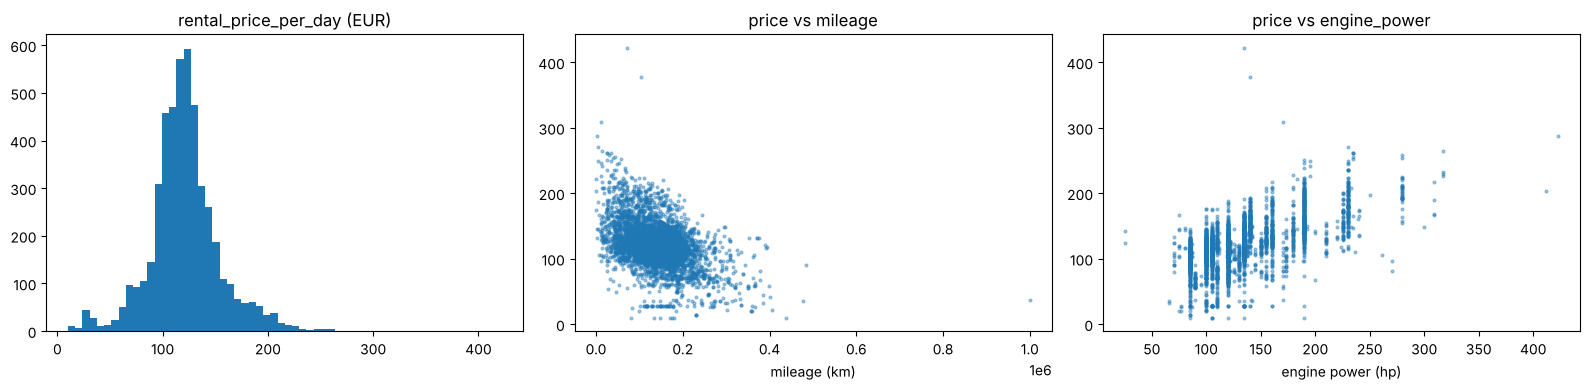

,mileage,engine_power,rental_price_per_day
mileage,1.00,-0.05,-0.45
engine_power,-0.05,1.00,0.63
rental_price_per_day,-0.45,0.63,1.00


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(df['rental_price_per_day'], bins=60); ax[0].set_title('rental_price_per_day (EUR)')
ax[1].scatter(df['mileage'], df['rental_price_per_day'], s=4, alpha=0.4); ax[1].set_title('price vs mileage'); ax[1].set_xlabel('mileage (km)')
ax[2].scatter(df['engine_power'], df['rental_price_per_day'], s=4, alpha=0.4); ax[2].set_title('price vs engine_power'); ax[2].set_xlabel('engine power (hp)')
plt.tight_layout(); plt.show()
df[['mileage', 'engine_power', 'rental_price_per_day']].corr().round(2)

This cell looks at the categories and the options. The charts show the price by car type and the average price gap for each option: an automatic gearbox has the largest gap and winter tires the smallest. These gaps do not control for other characteristics. The output table gives the most frequent brands, led by Citroën (969 cars, median of 114 EUR).

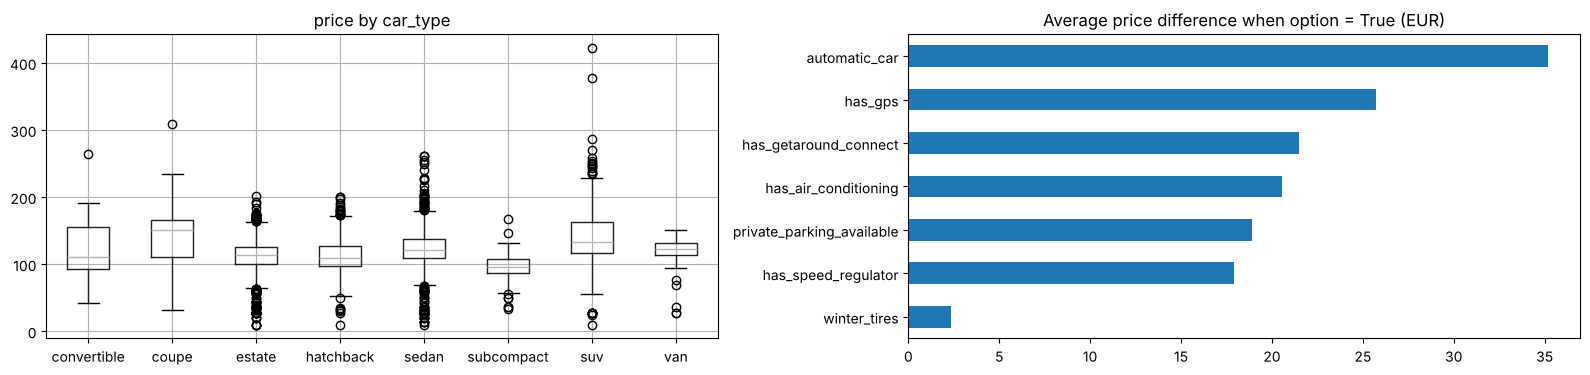

,count,median
model_key,,
Citroën,969,114.0
Renault,915,121.0
BMW,827,118.0
Peugeot,642,107.0
Audi,526,133.0
Nissan,274,114.0
Mitsubishi,231,184.0
Mercedes,97,120.0
Volkswagen,65,141.0


In [7]:
CAT = ['model_key', 'fuel', 'paint_color', 'car_type']
BOOL = ['private_parking_available', 'has_gps', 'has_air_conditioning', 'automatic_car',
        'has_getaround_connect', 'has_speed_regulator', 'winter_tires']
NUM = ['mileage', 'engine_power']
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
order = df.groupby('car_type')['rental_price_per_day'].median().sort_values().index
df.boxplot('rental_price_per_day', by='car_type', ax=axes[0], positions=range(len(order)))
axes[0].set_title('price by car_type'); axes[0].set_xlabel('')
uplift = {c: df.loc[df[c], 'rental_price_per_day'].mean() - df.loc[~df[c], 'rental_price_per_day'].mean() for c in BOOL}
pd.Series(uplift).sort_values().plot.barh(ax=axes[1], title='Average price difference when option = True (EUR)')
plt.suptitle(''); plt.tight_layout(); plt.show()
df.groupby('model_key')['rental_price_per_day'].agg(['count', 'median']).sort_values('count', ascending=False).head(12)

Main drivers: engine power (strong positive link), mileage (negative), options such as GPS and Getaround Connect, and the brand. The permutation importance below shows that private parking weighs very little in the model. 28 brands but most of them are rare: brands with fewer than 10 cars are grouped by the encoder into an "infrequent" category.

## 3. Preprocessing and train/test split

This cell separates 20% of the cars for the final test, so that the score is measured on cars never seen. The output shows 3,872 cars for training and 969 for test. The preprocessor standardises the numeric columns and encodes the categories in one-hot. Brands with fewer than 10 cars are grouped, and an unknown category is accepted, which matters for an API.

In [8]:
FEATURES = ['model_key', 'mileage', 'engine_power', 'fuel', 'paint_color', 'car_type',
            'private_parking_available', 'has_gps', 'has_air_conditioning', 'automatic_car',
            'has_getaround_connect', 'has_speed_regulator', 'winter_tires']
TARGET = 'rental_price_per_day'
X, y = df[FEATURES].copy(), df[TARGET]
X[BOOL] = X[BOOL].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), NUM),
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=10, sparse_output=False), CAT),
        ('bool', 'passthrough', BOOL),
    ])

(3872, 13) (969, 13)


## 4. Model comparison (5-fold cross-validation on the training set, tracked with MLflow)

This cell compares four models with the same 5-fold cross-validation, and records each one in MLflow as a run, with its parameters and scores. MLflow works here as a local experiment notebook, in a SQLite file. The settings of these models are usual values.

The output shows a cross-validated R² of 0.757 for gradient boosting, 0.748 for the random forest, 0.696 for Ridge and 0.695 for linear regression. The gap of 0.009 between the two tree models is smaller than the variation between folds, about 0.05, so they are tied. The clear gap separates tree models from linear models.

In [9]:
import mlflow
mlflow.set_tracking_uri('sqlite:///mlflow.db')  # local tracking; browse with: mlflow ui --backend-store-uri sqlite:///mlflow.db
mlflow.set_experiment('getaround_pricing')

candidates = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=SEED),
}
cv = KFold(5, shuffle=True, random_state=SEED)
rows = []
for name, est in candidates.items():
    pipe = Pipeline([('prep', make_preprocessor()), ('model', est)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=('r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error'))
    row = {'model': name, 'cv_r2': res['test_r2'].mean(), 'cv_r2_std': res['test_r2'].std(),
           'cv_mae': -res['test_neg_mean_absolute_error'].mean(), 'cv_rmse': -res['test_neg_root_mean_squared_error'].mean()}
    rows.append(row)
    with mlflow.start_run(run_name=f'cv_{name}'):
        mlflow.log_params({'model': name, **{k: v for k, v in est.get_params().items() if isinstance(v, (int, float, str)) and v is not None}})
        mlflow.log_metrics({k: v for k, v in row.items() if k != 'model'})
cv_results = pd.DataFrame(rows).set_index('model').round(3).sort_values('cv_r2', ascending=False)
cv_results

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/10/07 21:50:39 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/07 21:50:39 INFO mlflow.store.db.utils: Updating database tables


2026/10/07 21:50:40 INFO mlflow.tracking.fluent: Experiment with name 'getaround_pricing' does not exist. Creating a new experiment.


,cv_r2,cv_r2_std,cv_mae,cv_rmse
model,,,,
HistGradientBoosting,0.757,0.047,10.734,16.503
RandomForest,0.748,0.052,10.845,16.782
Ridge,0.696,0.050,12.345,18.485
LinearRegression,0.695,0.049,12.355,18.509


## 5. Hyperparameter tuning of the best family (gradient boosting)

This cell tests 16 combinations of 4 settings with the same cross-validation, to see whether gradient boosting can improve. The output keeps a learning rate of 0.05, 600 iterations, 15 leaves and no L2 penalty, with a cross-validated R² of 0.7592. The gain is small. These 16 combinations are not recorded in MLflow: only the best one is.

In [10]:
pipe = Pipeline([('prep', make_preprocessor()), ('model', HistGradientBoostingRegressor(random_state=SEED))])
grid = {
    'model__learning_rate': [0.05, 0.1],
    'model__max_iter': [300, 600],
    'model__max_leaf_nodes': [15, 31],
    'model__l2_regularization': [0.0, 1.0],
}
search = GridSearchCV(pipe, grid, cv=cv, scoring='r2', n_jobs=-1)
search.fit(X_train, y_train)
print('Best params:', search.best_params_)
print(f'Best CV R2: {search.best_score_:.4f}')
best_model = search.best_estimator_

Best params: {'model__l2_regularization': 0.0, 'model__learning_rate': 0.05, 'model__max_iter': 600, 'model__max_leaf_nodes': 15}
Best CV R2: 0.7592


## 6. Evaluation on the held-out test set

This cell measures the tuned model on the 969 test cars, and compares it to a baseline that always predicts the mean price. The output shows an R² of 0.757 and a mean error of 10.5 EUR, against -0.004 and 23.6 EUR for the baseline. The cross-validated and test scores are not measured on the same data, so they do not compare directly. This run is recorded in MLflow.

In [11]:
pred = best_model.predict(X_test)
baseline = np.full_like(pred, y_train.mean(), dtype=float)
test_scores = pd.DataFrame({
    'R2': [r2_score(y_test, pred), r2_score(y_test, baseline)],
    'MAE (EUR)': [mean_absolute_error(y_test, pred), mean_absolute_error(y_test, baseline)],
    'RMSE (EUR)': [root_mean_squared_error(y_test, pred), root_mean_squared_error(y_test, baseline)],
}, index=['Tuned HistGradientBoosting', 'Baseline (mean price)']).round(3)
with mlflow.start_run(run_name='final_hist_gradient_boosting'):
    mlflow.log_params(search.best_params_)
    mlflow.log_metrics({'test_r2': test_scores.iloc[0, 0], 'test_mae': test_scores.iloc[0, 1], 'test_rmse': test_scores.iloc[0, 2]})
test_scores

,R2,MAE (EUR),RMSE (EUR)
Tuned HistGradientBoosting,0.757,10.548,16.310
Baseline (mean price),-0.004,23.599,33.141


These charts compare predicted and actual prices, then show the errors. Points close to the diagonal are good predictions, so the charts show where the model misses. There is no table output.

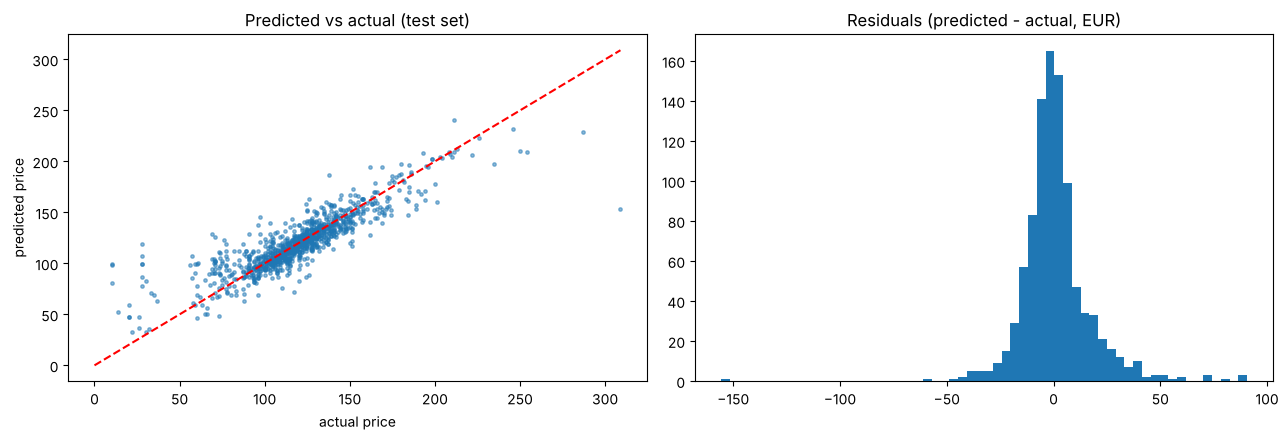

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test, pred, s=6, alpha=0.5); lim = [0, max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, 'r--'); ax[0].set_xlabel('actual price'); ax[0].set_ylabel('predicted price'); ax[0].set_title('Predicted vs actual (test set)')
ax[1].hist(pred - y_test, bins=60); ax[1].set_title('Residuals (predicted - actual, EUR)')
plt.tight_layout(); plt.show()

### Feature importance (permutation on the test set)

This cell shuffles each column in turn and measures the drop in R², to see what the model really uses. The chart shows engine power first, then mileage, far ahead of brand and car type. Winter tires, private parking and air conditioning weigh very little.

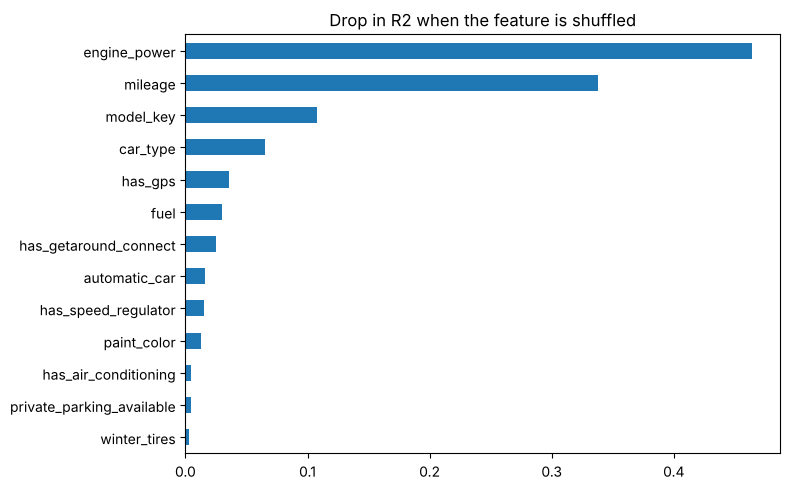

In [13]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=SEED, scoring='r2')
pd.Series(imp.importances_mean, index=FEATURES).sort_values().plot.barh(figsize=(8, 5), title='Drop in R2 when the feature is shuffled')
plt.tight_layout(); plt.show()

## 7. Export the model for the API

The model is retrained on **all** cleaned data with the best hyperparameters, then saved with its metadata (feature order expected by `/predict`). This uses all the data for production, but this deployed model has no test score of its own and no MLflow run. It is not stored in MLflow either. The output confirms that the two files are saved.

In [14]:
final_model = Pipeline([('prep', make_preprocessor()), ('model', HistGradientBoostingRegressor(random_state=SEED))])
final_model.set_params(**search.best_params_)
final_model.fit(X, y)
os.makedirs('../api', exist_ok=True)
joblib.dump(final_model, '../api/model.joblib')
meta = {'features': FEATURES, 'categorical': CAT, 'boolean': BOOL, 'numeric': NUM,
        'test_r2': float(test_scores.iloc[0, 0]), 'test_mae': float(test_scores.iloc[0, 1]),
        'categories': {c: sorted(df[c].unique().tolist()) for c in CAT}}
with open('../api/model_meta.json', 'w') as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)
print('Saved ../api/model.joblib and ../api/model_meta.json')

Saved ../api/model.joblib and ../api/model_meta.json


This cell checks the saved model with the same input format as the API, so that a format error would appear here. The output gives 107.8 and 133.9 EUR per day for the two example cars.

In [15]:
# sanity check: same input format as the API
example = [['Citroën', 140411, 100, 'diesel', 'black', 'convertible', True, True, False, False, True, True, True],
           ['Peugeot', 72000, 110, 'petrol', 'grey', 'estate', False, True, True, False, True, False, False]]
ex = pd.DataFrame(example, columns=FEATURES); ex[BOOL] = ex[BOOL].astype(int)
joblib.load('../api/model.joblib').predict(ex).round(1)

array([107.8, 133.9])

This cell states the performance on the test set: R² of 0.757, mean error of 10.5 EUR and RMSE of 16.3 EUR, for a mean price of 121 EUR per day. The model predicts the price of similar cars in this file. The file has no demand data, so it does not prove that this price maximises the income of an owner.

In [16]:
print(f"Test set performance: R2 = {test_scores.iloc[0, 0]:.3f}, MAE = {test_scores.iloc[0, 1]:.1f} EUR, RMSE = {test_scores.iloc[0, 2]:.1f} EUR "
      f"(baseline MAE {test_scores.iloc[1, 1]:.1f} EUR, mean price {y.mean():.0f} EUR/day)")

Test set performance: R2 = 0.757, MAE = 10.5 EUR, RMSE = 16.3 EUR (baseline MAE 23.6 EUR, mean price 121 EUR/day)
